In [1]:
import sys
import time
import importlib.util
from pathlib import Path

def find_project_root(start_path=None):
    if start_path is None:
        start_path = Path.cwd()
    else:
        start_path = Path(start_path)

    current = start_path.resolve()

    while True:
        if (current / "09_config.py").exists() and (current / "08_utils.py").exists():
            return current
        if current.parent == current:
            raise FileNotFoundError("Project root tidak ditemukan.")
        current = current.parent

def import_py_file(module_name, file_path):
    file_path = Path(file_path).resolve()
    spec = importlib.util.spec_from_file_location(module_name, file_path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[module_name] = module
    spec.loader.exec_module(module)
    return module

PROJECT_ROOT = find_project_root()
cfg = import_py_file("ferplus_config", PROJECT_ROOT / "09_config.py")
utils = import_py_file("ferplus_utils", PROJECT_ROOT / "08_utils.py")

utils.set_global_seed(cfg.SEED)
utils.ensure_directories()

print(cfg.SCENARIO_NOTES["model_1"])
print("Train dir:", cfg.TRAIN_NON_AUGMENTED_DIR)
print("Validation dir:", cfg.VALIDATION_NON_AUGMENTED_DIR)
print("Test dir:", cfg.TEST_DIR)

TensorFlow op determinism: ENABLED
Model 1 menggunakan training_non_augmented sebagai baseline. Tidak menggunakan augmentation tambahan, tidak menggunakan class_weight, tidak menggunakan oversampling/undersampling, dan tidak menggunakan fine-tuning.
Train dir: C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\training_non_augmented
Validation dir: C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\validation_non_augmented
Test dir: C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\test


In [2]:
train_ds, validation_ds, test_ds = utils.load_datasets_for_scenario("model_1")

for images, labels in train_ds.take(1):
    print("Batch image shape:", images.shape)
    print("Batch label shape:", labels.shape)
    print("Pixel min:", images.numpy().min())
    print("Pixel max:", images.numpy().max())
    print("Contoh label:", labels.numpy()[:10])

Found 28558 files belonging to 8 classes.
Found 3579 files belonging to 8 classes.
Found 3573 files belonging to 8 classes.
Batch image shape: (32, 224, 224, 3)
Batch label shape: (32,)
Pixel min: 0.0
Pixel max: 255.0
Contoh label: [5 6 4 5 5 5 4 4 5 5]


In [3]:
model_1 = utils.build_efficientnetb0_model(
    model_name=cfg.MODEL_1_NAME,
    use_augmentation=False,
    base_trainable=False,
    learning_rate=cfg.LEARNING_RATE_HEAD
)

model_1.summary()


TensorFlow op determinism: ENABLED
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "model_1_baseline_no_augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_head (Dense)     │ (None, 8)              │        10,248 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,059,819 (15.49 MB)

 Trainable params: 10,248 (40.03 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [4]:
callbacks = utils.get_callbacks(
    run_name=cfg.MODEL_1_NAME,
    checkpoint_path=cfg.MODEL_1_BEST_PATH,
    monitor="val_accuracy"
)

start_time = time.time()

history_1 = model_1.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=cfg.MAX_EPOCHS_HEAD,
    callbacks=callbacks,
    verbose=1
)

training_duration = time.time() - start_time

training_time_info = {
    "model": cfg.MODEL_1_NAME,
    "scenario": "Model 1 baseline no augmentation",
    "train_dir": str(cfg.TRAIN_NON_AUGMENTED_DIR),
    "validation_dir": str(cfg.VALIDATION_NON_AUGMENTED_DIR),
    "duration_seconds": training_duration,
    "duration_formatted": utils.format_seconds(training_duration)
}

training_time_path = cfg.LOG_DIR / f"{cfg.MODEL_1_NAME}_training_time.json"
utils.save_json(training_time_info, training_time_path)

print("Waktu training:", utils.format_seconds(training_duration))
print("Info waktu training disimpan ke:", training_time_path)

Epoch 1/30
893/893 ━━━━━━━━━━━━━━━━━━━━ 0s 376ms/step - accuracy: 0.4943 - loss: 1.3623
Epoch 1: val_accuracy improved from -inf to 0.61554, saving model to C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\models\model_1_baseline_no_augmentation_best.keras
893/893 ━━━━━━━━━━━━━━━━━━━━ 385s 425ms/step - accuracy: 0.4944 - loss: 1.3622 - val_accuracy: 0.6155 - val_loss: 1.0817 - learning_rate: 0.0010
Epoch 2/30
893/893 ━━━━━━━━━━━━━━━━━━━━ 0s 364ms/step - accuracy: 0.6042 - loss: 1.1013
Epoch 2: val_accuracy improved from 0.61554 to 0.64599, saving model to C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\models\model_1_baseline_no_augmentation_best.keras
893/893 ━━━━━━━━━━━━━━━━━━━━ 368s 412ms/step - accuracy: 0.6042 - loss: 1.1013 - val_accuracy: 0.6460 - val_loss: 1.0072 - learning_rate: 0.0010
Epoch 3/30
893/893 ━━━━━━━━━━━━━━━━━━━━ 0s 380ms/step - accuracy: 0.6218 - loss: 1.0546
Epoch 3: val_accuracy improved from 0.64599 to 0.66443, saving model to C:\Users\Davin\Do

Best model: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\models\model_1_baseline_no_augmentation_best.keras
Final model: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\models\model_1_baseline_no_augmentation_final.keras


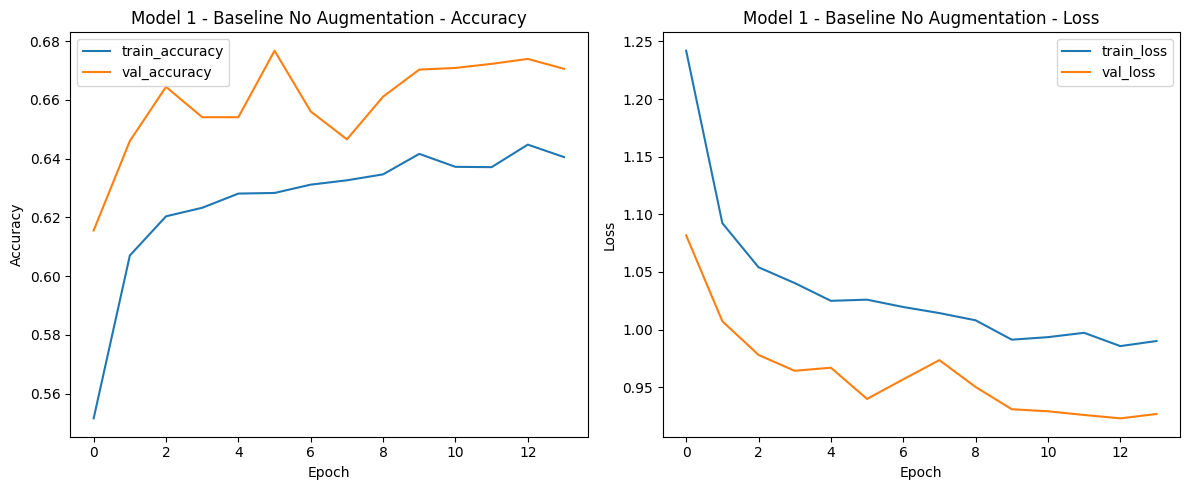

Grafik training disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\figures\training_history_model_1_baseline_no_augmentation.png


In [5]:
model_1.save(cfg.MODEL_1_FINAL_PATH)

print("Best model:", cfg.MODEL_1_BEST_PATH)
print("Final model:", cfg.MODEL_1_FINAL_PATH)

history_fig_path = cfg.FIGURE_DIR / "training_history_model_1_baseline_no_augmentation.png"

utils.plot_training_history(
    history=history_1,
    title="Model 1 - Baseline No Augmentation",
    save_path=history_fig_path
)

print("Grafik training disimpan ke:", history_fig_path)

In [6]:
val_loss, val_accuracy = model_1.evaluate(validation_ds, verbose=1)

print("Validation loss:", val_loss)
print("Validation accuracy:", val_accuracy)

112/112 ━━━━━━━━━━━━━━━━━━━━ 31s 274ms/step - accuracy: 0.5867 - loss: 1.2016
Validation loss: 0.9397568702697754
Validation accuracy: 0.6767253279685974
